# What Drives Silver-Zinc Battery Life? A Multiple Regression Analysis

**Author:** Alana Lee

Researchers testing silver-zinc batteries for satellites recorded how many charge/discharge **cycles** each battery lasted before failing, under 20 different operating conditions. This notebook asks which operating conditions predict battery life, and how well we can forecast it for a new set of conditions.

| Variable | Meaning | Units |
|---|---|---|
| `X1` | Charge rate | amps |
| `X2` | Discharge rate | amps |
| `X3` | Depth of discharge | % of rated ampere-hours |
| `X4` | Temperature | °C |
| `X5` | End-of-charge voltage | volts |
| `Y`  | Cycles to failure | count |

**Approach.** I compare candidate models with tools that penalize complexity (adjusted R², AIC/BIC and leave-one-out cross-validation), because plain R² always rises when variables are added. I check multicollinearity with variance inflation factors (VIF) and check the regression assumptions with residual plots and formal tests.

> This is a revised version of a course project (EMSE 4765, George Washington University, Spring 2024). The **"What changed from the original analysis"** section at the end lists the methods I corrected and how the conclusion changed.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.anova import anova_lm
from scipy import stats

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("data/battery_cycles.csv")
df.columns = ["X1", "X2", "X3", "X4", "X5", "Y"]
df["logY"] = np.log10(df["Y"])
PREDICTORS = ["X1", "X2", "X3", "X4", "X5"]
LABELS = {"X1": "Charge rate (A)", "X2": "Discharge rate (A)", "X3": "Depth of discharge (%)",
          "X4": "Temperature (°C)", "X5": "End-of-charge voltage (V)"}
df

,X1,X2,X3,X4,X5,Y,logY
0,0.375,3.13,60.0,40,2.00,101,2.0043
1,1.000,3.13,76.8,30,1.99,141,2.1492
2,1.000,3.13,60.0,20,2.00,96,1.9823
3,1.000,3.13,60.0,20,1.98,125,2.0969
4,1.625,3.13,43.2,10,2.01,43,1.6335
5,1.625,3.13,60.0,20,2.00,16,1.2041
6,1.625,3.13,60.0,20,2.02,188,2.2742
7,0.375,5.00,76.8,10,2.01,10,1.0000
8,1.000,5.00,43.2,10,1.99,3,0.4771
9,1.000,5.00,43.2,30,2.01,386,2.5866


## 1. Exploring the data

Only 20 observations, so every extra parameter costs a lot. The predictors take a few fixed levels, which suggests a designed experiment.

In [2]:
df.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
X1,1.0312,0.4745,0.375,1.6250
X2,3.0335,1.4236,1.250,5.0000
X3,62.8400,15.4636,43.200,100.0000
X4,19.5000,9.9868,0.000,40.0000
X5,1.9990,0.0097,1.980,2.0200
Y,112.3000,104.6876,2.000,386.0000
logY,1.7371,0.6875,0.301,2.5866


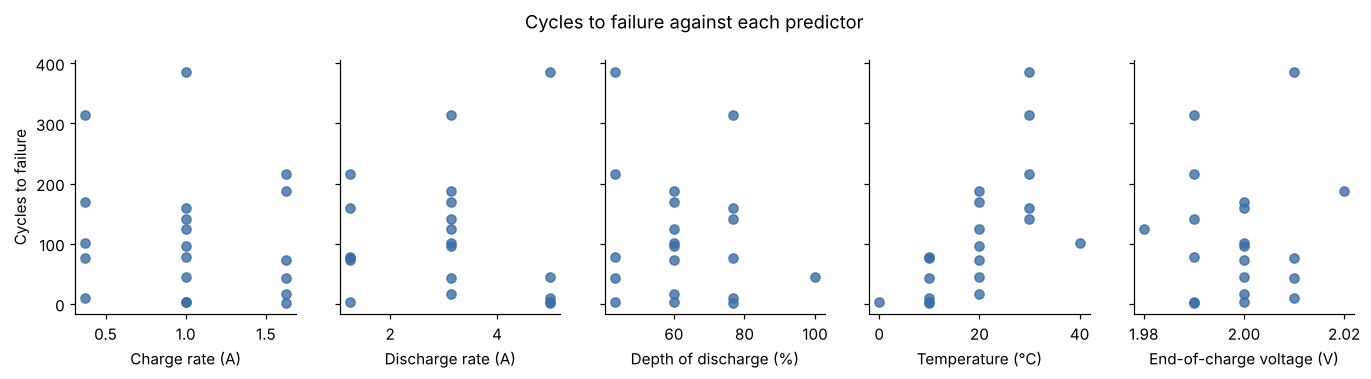

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharey=True)
for ax, x in zip(axes, PREDICTORS):
    ax.scatter(df[x], df["Y"], color="#3b6ea5", alpha=0.8)
    ax.set_xlabel(LABELS[x])
axes[0].set_ylabel("Cycles to failure")
fig.suptitle("Cycles to failure against each predictor", y=1.03)
plt.show()

Temperature shows the clearest relationship. The response is strongly right-skewed (2 to 386 cycles), which suggests the error variance may grow with the mean. Section 2 tests that.

## 2. Choosing the response: Y or log(Y)?

Comparing the residual standard deviation of a model for Y (cycles) with one for log(Y) (log-cycles) means nothing, because they're in different units. Instead I fit the same full model both ways and compare **assumption checks**. I also run a **Box–Cox** analysis, which estimates the power transformation that best fits the data.

In [4]:
full_formula = " + ".join(PREDICTORS)
m_raw = smf.ols(f"Y ~ {full_formula}", df).fit()
m_log = smf.ols(f"logY ~ {full_formula}", df).fit()

def assumption_checks(m):
    return {
        "Shapiro–Wilk p (normal residuals)": stats.shapiro(m.resid).pvalue,
        "Breusch–Pagan p (constant variance)": het_breuschpagan(m.resid, m.model.exog)[1],
        "Adjusted R²": m.rsquared_adj,
    }

pd.DataFrame({"Y": assumption_checks(m_raw), "log10(Y)": assumption_checks(m_log)})

,Y,log10(Y)
Shapiro–Wilk p (normal residuals),0.1322,0.1988
Breusch–Pagan p (constant variance),0.0315,0.5507
Adjusted R²,0.3487,0.5430


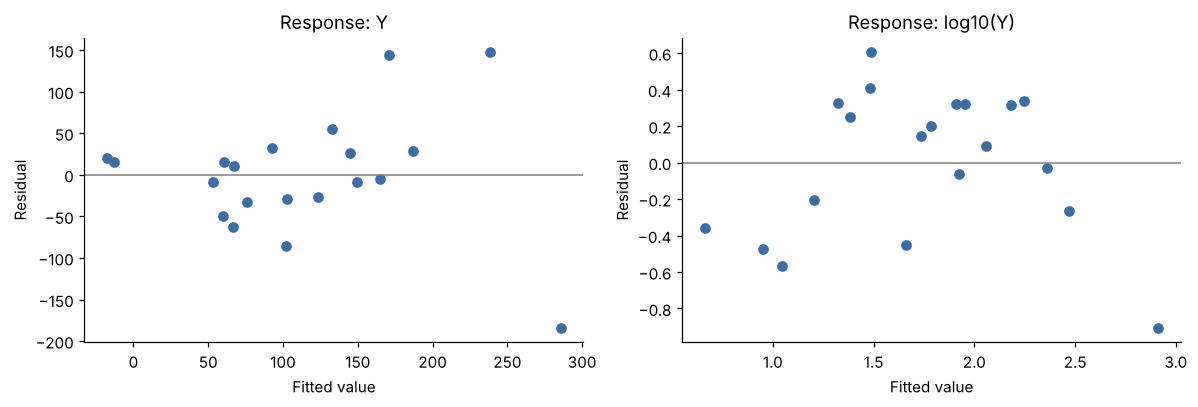

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, m, title in [(axes[0], m_raw, "Response: Y"), (axes[1], m_log, "Response: log10(Y)")]:
    ax.scatter(m.fittedvalues, m.resid, color="#3b6ea5")
    ax.axhline(0, color="grey", lw=1)
    ax.set(title=title, xlabel="Fitted value", ylabel="Residual")
plt.tight_layout(); plt.show()

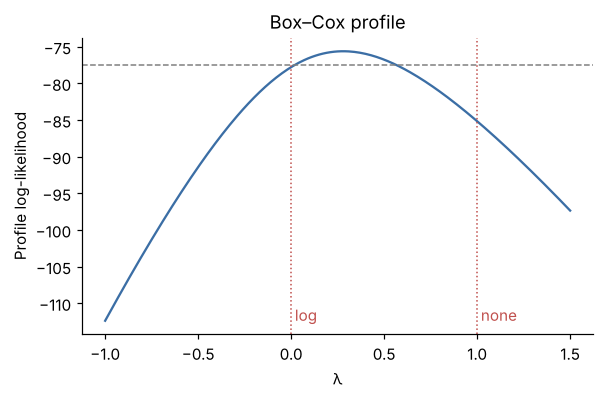

Best λ = 0.28, 95% CI ≈ [0.02, 0.56]


In [6]:
# Box–Cox profile log-likelihood for the full main-effects model
X_full = sm.add_constant(df[PREDICTORS])
n = len(df)
gm = np.exp(np.mean(np.log(df["Y"])))  # geometric mean, makes SSR comparable across lambda
lambdas = np.linspace(-1, 1.5, 251)

def boxcox_ll(lam):
    z = np.log(df["Y"]) * gm if abs(lam) < 1e-9 else (df["Y"] ** lam - 1) / (lam * gm ** (lam - 1))
    ssr = sm.OLS(z, X_full).fit().ssr
    return -n / 2 * np.log(ssr / n)

ll = np.array([boxcox_ll(l) for l in lambdas])
lam_hat = lambdas[ll.argmax()]
ci = lambdas[ll >= ll.max() - stats.chi2.ppf(0.95, 1) / 2]

plt.figure(figsize=(6, 3.5))
plt.plot(lambdas, ll, color="#3b6ea5")
plt.axhline(ll.max() - stats.chi2.ppf(0.95, 1) / 2, ls="--", color="grey", lw=1)
for v, lab in [(0, "log"), (1, "none")]:
    plt.axvline(v, color="#c0504d", lw=1, ls=":"); plt.text(v + 0.02, ll.min(), lab, color="#c0504d")
plt.xlabel("λ"); plt.ylabel("Profile log-likelihood"); plt.title("Box–Cox profile")
plt.show()
print(f"Best λ = {lam_hat:.2f}, 95% CI ≈ [{ci.min():.2f}, {ci.max():.2f}]")

**Decision: model log10(Y).**

* With the raw response, the Breusch–Pagan test rejects constant variance (p ≈ 0.03), and the residuals fan out as fitted values grow. On the log scale that problem disappears (p ≈ 0.55).
* Box–Cox clearly rules out leaving Y untransformed (λ = 1 is far outside the interval). The best λ is about 0.3, and the interval just barely excludes 0 (the log). I use the log anyway because it's close to optimal and much easier to interpret: each coefficient becomes a *percentage* change in battery life. Appendix A checks that using λ = 0.3 instead leads to the same model.

## 3. Correlation and multicollinearity

Multicollinearity means predictors are correlated with **each other**, which inflates the uncertainty of their coefficients. The right diagnostic is the **variance inflation factor (VIF)**. The Durbin–Watson statistic tests something else entirely (autocorrelation in the residuals; see section 6).

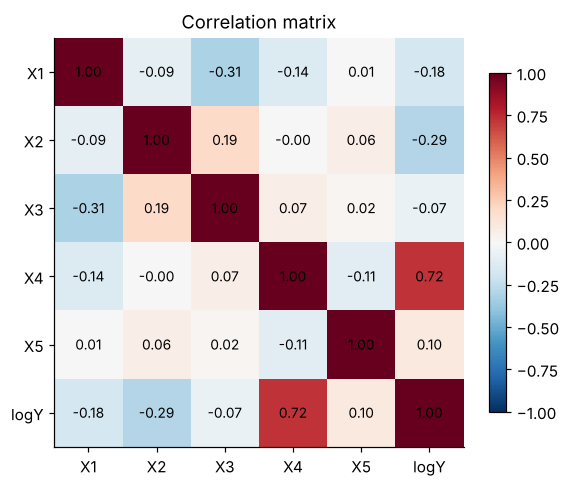

In [7]:
corr = df[PREDICTORS + ["logY"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, shrink=0.8); ax.set_title("Correlation matrix")
plt.show()

In [8]:
vif = pd.Series(
    [variance_inflation_factor(X_full.values, i) for i in range(1, X_full.shape[1])],
    index=PREDICTORS, name="VIF")
vif.to_frame()

,VIF
X1,1.1269
X2,1.0433
X3,1.1453
X4,1.0332
X5,1.0177


Every VIF is about 1.0–1.15, far below the usual concern threshold of 5–10. The predictors are close to uncorrelated (as you'd expect from a designed experiment), so **multicollinearity isn't a problem**, and each coefficient can be read on its own terms.

Temperature has the strongest correlation with log(Y) (r ≈ 0.72), followed by discharge rate (r ≈ −0.29).

## 4. Model selection

Rather than adding variables one by one as correlation cutoffs are lowered, I fit **every** combination of the five predictors (2⁵ − 1 = 31 models) and compare them on criteria that penalize complexity:

* **Adjusted R²**: R² adjusted for the number of predictors (higher is better).
* **AIC / BIC**: information criteria. BIC penalizes extra parameters more heavily (lower is better).
* **LOOCV MSE**: leave-one-out cross-validation error. Each point is predicted by a model fitted without it, which directly measures out-of-sample accuracy (lower is better). For OLS it has the closed form mean[(eᵢ / (1 − hᵢᵢ))²].

In [9]:
def loocv_mse(model):
    h = model.get_influence().hat_matrix_diag
    return np.mean((model.resid / (1 - h)) ** 2)

def summarize(formula):
    m = smf.ols(formula, df).fit()
    return {"model": formula.replace("logY ~ ", ""), "k": int(m.df_model), "R²": m.rsquared,
            "Adj R²": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic, "LOOCV MSE": loocv_mse(m)}

subsets = [c for k in range(1, 6) for c in itertools.combinations(PREDICTORS, k)]
results = pd.DataFrame([summarize("logY ~ " + " + ".join(c)) for c in subsets])
results.sort_values("LOOCV MSE").head(8).reset_index(drop=True)

,model,k,R²,Adj R²,AIC,BIC,LOOCV MSE
0,X2 + X4,2,0.6006,0.5536,28.3852,31.3724,0.2720
1,X2 + X4 + X5,3,0.6421,0.5750,28.1922,32.1751,0.2743
2,X4,1,0.5169,0.4900,30.1933,32.1847,0.2816
3,X2 + X3 + X4 + X5,4,0.6464,0.5522,29.9477,34.9263,0.2994
4,X4 + X5,2,0.5509,0.4981,30.7311,33.7183,0.2998
5,X3 + X4,2,0.5306,0.4754,31.6155,34.6027,0.3015
6,X1 + X2 + X4,3,0.6116,0.5388,29.8289,33.8118,0.3046
7,X2 + X3 + X4,3,0.6046,0.5304,30.1872,34.1701,0.3065


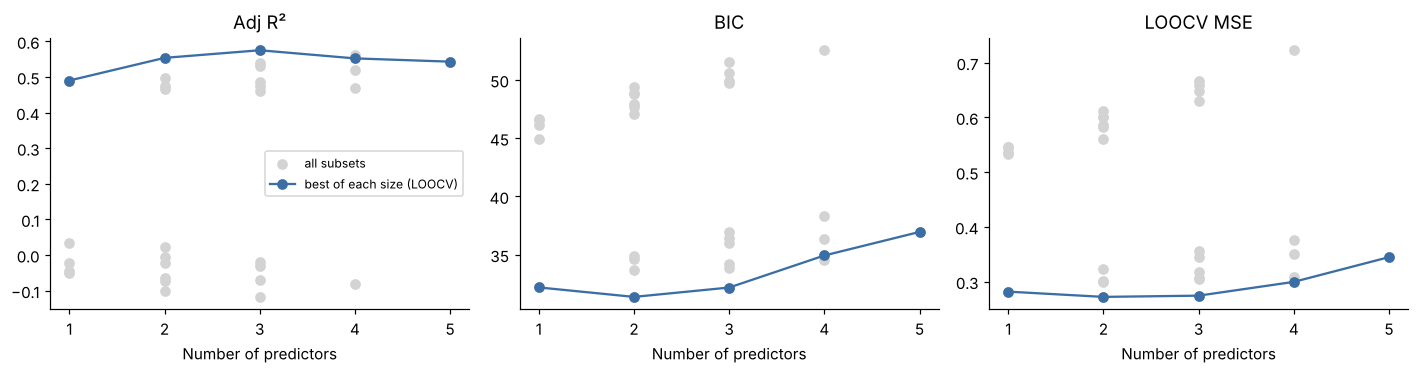

In [10]:
best = results.loc[results.groupby("k")["LOOCV MSE"].idxmin()]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["Adj R²", "BIC", "LOOCV MSE"]):
    ax.scatter(results["k"], results[col], color="lightgrey", label="all subsets")
    ax.plot(best["k"], best[col], "o-", color="#3b6ea5", label="best of each size (LOOCV)")
    ax.set(xlabel="Number of predictors", title=col, xticks=range(1, 6))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Two models stand out:

* **X2 + X4** (discharge rate + temperature) has the **lowest BIC and lowest LOOCV error**.
* **X2 + X4 + X5** has the lowest AIC and the highest adjusted R², but only slightly, and its cross-validation error is no better.

A nested F-test checks whether adding end-of-charge voltage (X5) is justified:

In [11]:
m_24 = smf.ols("logY ~ X2 + X4", df).fit()
m_245 = smf.ols("logY ~ X2 + X4 + X5", df).fit()
m_full = smf.ols(f"logY ~ {full_formula}", df).fit()
print("X2+X4  vs  X2+X4+X5:"); print(anova_lm(m_24, m_245).round(4))
print("\nX2+X4  vs  all five main effects:"); print(anova_lm(m_24, m_full).round(4))

X2+X4  vs  X2+X4+X5:
   df_resid     ssr  df_diff  ss_diff       F  Pr(>F)
0      17.0  3.5863      0.0      NaN     NaN     NaN
1      16.0  3.2138      1.0   0.3724  1.8542  0.1922

X2+X4  vs  all five main effects:
   df_resid     ssr  df_diff  ss_diff       F  Pr(>F)
0      17.0  3.5863      0.0      NaN     NaN     NaN
1      14.0  3.0238      3.0   0.5625  0.8681  0.4807


Neither X5 alone nor the remaining three predictors together improve the model significantly (p > 0.05). With only 20 observations, I choose the simpler **X2 + X4** model.

## 5. Do interaction terms help?

An interaction term says *the effect of one variable depends on the level of another*, for example whether high temperatures hurt more at high discharge rates. Two predictors being correlated with each other is **not** a reason to include their interaction. To test each possible interaction fairly, I add it to the full main-effects model one at a time, **always keeping both of its main effects** (the hierarchy principle).

In [12]:
rows = []
for a, b in itertools.combinations(PREDICTORS, 2):
    m = smf.ols(f"logY ~ {full_formula} + {a}:{b}", df).fit()
    rows.append({"interaction": f"{a}×{b}", "p-value": m.pvalues[f"{a}:{b}"],
                 "Adj R²": m.rsquared_adj, "LOOCV MSE": loocv_mse(m)})
inter = pd.DataFrame(rows).sort_values("p-value").reset_index(drop=True)
inter["Bonferroni p"] = (inter["p-value"] * len(inter)).clip(upper=1)
print(f"Main-effects-only model: Adj R² = {m_full.rsquared_adj:.4f}, LOOCV MSE = {loocv_mse(m_full):.4f}")
inter

Main-effects-only model: Adj R² = 0.5430, LOOCV MSE = 0.3446


,interaction,p-value,Adj R²,LOOCV MSE,Bonferroni p
0,X1×X5,0.2241,0.5627,0.3397,1.0
1,X1×X4,0.2696,0.5535,0.4356,1.0
2,X2×X5,0.2883,0.5503,0.3982,1.0
3,X1×X3,0.3837,0.5368,0.3676,1.0
4,X2×X4,0.4361,0.5311,0.3873,1.0
5,X3×X5,0.5542,0.5214,0.3816,1.0
6,X2×X3,0.5698,0.5204,0.3848,1.0
7,X4×X5,0.6189,0.5175,0.3814,1.0
8,X3×X4,0.7743,0.5111,0.3807,1.0
9,X1×X2,0.9389,0.5081,0.3906,1.0


None of the 10 interactions is significant (smallest p ≈ 0.22, before any multiple-testing correction), and every one makes cross-validation error worse. **The data contain no evidence of interactions.**

### Revisiting the original "best" model

The original report chose X1 + X2 + X4 + X5 + X1×X3 + X2×X3 because it had the highest R² (68.6%). Here's how it compares once complexity is accounted for:

In [13]:
compare = pd.DataFrame([
    summarize("logY ~ X4"),
    summarize("logY ~ X2 + X4"),
    summarize("logY ~ X1 + X2 + X4 + X5"),
    summarize("logY ~ X1 + X2 + X4 + X5 + X1:X3 + X2:X3"),
    summarize("logY ~ X1 + X2 + X3 + X4 + X5 + X1:X3 + X2:X3"),
])
compare.insert(0, "label", ["Temperature only", "Chosen model", "Original model 3",
                            "Original final model", "Original final + X3 (hierarchical)"])
compare

,label,model,k,R²,Adj R²,AIC,BIC,LOOCV MSE
0,Temperature only,X4,1,0.5169,0.4900,30.1933,32.1847,0.2816
1,Chosen model,X2 + X4,2,0.6006,0.5536,28.3852,31.3724,0.2720
2,Original model 3,X1 + X2 + X4 + X5,4,0.6529,0.5604,29.5772,34.5559,0.3080
3,Original final model,X1 + X2 + X4 + X5 + X1:X3 + X2:X3,6,0.6864,0.5416,31.5510,38.5211,0.3650
4,Original final + X3 (hierarchical),X1 + X2 + X3 + X4 + X5 + X1:X3 + X2:X3,7,0.6872,0.5048,33.4955,41.4613,0.4552


In [14]:
m_orig = smf.ols("logY ~ X1 + X2 + X4 + X5 + X1:X3 + X2:X3", df).fit()
print("Is the original model a significant improvement over X2 + X4? (nested F-test)")
print(anova_lm(m_24, m_orig).round(4))

Is the original model a significant improvement over X2 + X4? (nested F-test)
   df_resid     ssr  df_diff  ss_diff       F  Pr(>F)
0      17.0  3.5863      0.0      NaN     NaN     NaN
1      13.0  2.8162      4.0     0.77  0.8886  0.4978


The original model has the highest R², but **lower adjusted R², higher BIC and about 34% higher cross-validation error** than X2 + X4. Its four extra terms don't significantly improve the fit (F-test p > 0.05). Its higher R² comes from fitting noise, which is the overfitting risk when you select a model by R² alone.

## 6. Final model: log10(Cycles) ~ Discharge rate + Temperature

In [15]:
final = m_24
print(final.summary())

                            OLS Regression Results                            
Dep. Variable:                   logY   R-squared:                       0.601
Model:                            OLS   Adj. R-squared:                  0.554
Method:                 Least Squares   F-statistic:                     12.78
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           0.000409
Time:                        20:21:17   Log-Likelihood:                -11.193
No. Observations:                  20   AIC:                             28.39
Df Residuals:                      17   BIC:                             31.37
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1971      0.322      3.720      0.0

In [16]:
coef = final.params
ci_ = final.conf_int()
effects = pd.DataFrame({
    "change per unit": ["+1 A discharge rate", "+1 °C temperature"],
    "% change in cycles": [(10 ** coef[v] - 1) * 100 for v in ["X2", "X4"]],
    "95% CI low": [(10 ** ci_.loc[v, 0] - 1) * 100 for v in ["X2", "X4"]],
    "95% CI high": [(10 ** ci_.loc[v, 1] - 1) * 100 for v in ["X2", "X4"]],
}, index=["X2", "X4"])
effects.round(1)

,change per unit,% change in cycles,95% CI low,95% CI high
X2,+1 A discharge rate,-27.5,-49.4,3.8
X4,+1 °C temperature,12.1,6.5,17.9


**Interpretation** (holding the other variable fixed):

* Each **1 °C increase in temperature** is associated with about a **12% increase** in cycles to failure (95% CI: +6.5% to +18%, p < 0.001). Across the tested range (0–40 °C) that compounds to roughly a 95-fold difference.
* Each **1 A increase in discharge rate** is associated with about a **27% decrease** in cycles to failure, but this estimate is uncertain (95% CI: −49% to +4%, p ≈ 0.08). Discharge rate earns its place in the model because it improves cross-validated prediction, but the evidence for its effect is suggestive, not conclusive.
* The model explains about 60% of the variance in log-cycles (adjusted R² ≈ 0.55). The rest is unexplained battery-to-battery variation, which is large.

Charge rate, depth of discharge and end-of-charge voltage showed no detectable effect **in this sample**. With n = 20 that means "not enough evidence", not "no effect".

### Checking the assumptions

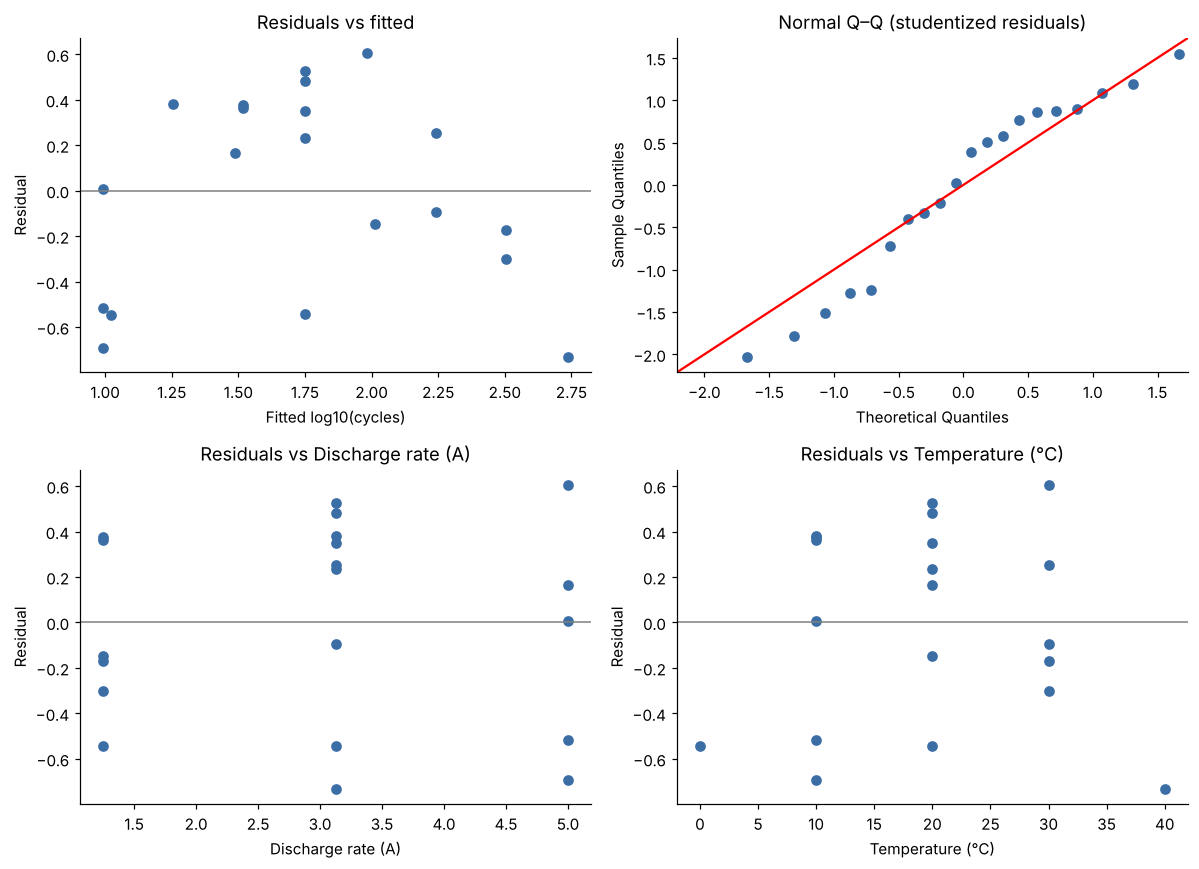

Shapiro–Wilk p = 0.100  (normality)
Breusch–Pagan p = 0.493  (constant variance)
Durbin–Watson = 2.02  (autocorrelation, only meaningful if rows are in time order)


In [17]:
infl = final.get_influence()
stud = infl.resid_studentized_external
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].scatter(final.fittedvalues, final.resid, color="#3b6ea5")
axes[0, 0].axhline(0, color="grey", lw=1)
axes[0, 0].set(title="Residuals vs fitted", xlabel="Fitted log10(cycles)", ylabel="Residual")

sm.qqplot(stud, line="45", ax=axes[0, 1], markerfacecolor="#3b6ea5", markeredgecolor="#3b6ea5")
axes[0, 1].set_title("Normal Q–Q (studentized residuals)")

for x, ax in [("X2", axes[1, 0]), ("X4", axes[1, 1])]:
    ax.scatter(df[x], final.resid, color="#3b6ea5"); ax.axhline(0, color="grey", lw=1)
    ax.set(title=f"Residuals vs {LABELS[x]}", xlabel=LABELS[x], ylabel="Residual")
plt.tight_layout(); plt.show()

dw = sm.stats.durbin_watson(final.resid)
print(f"Shapiro–Wilk p = {stats.shapiro(final.resid).pvalue:.3f}  (normality)")
print(f"Breusch–Pagan p = {het_breuschpagan(final.resid, final.model.exog)[1]:.3f}  (constant variance)")
print(f"Durbin–Watson = {dw:.2f}  (autocorrelation, only meaningful if rows are in time order)")

The residuals look like random scatter with no curvature or funnel shape, and the formal tests find no violations. The Durbin–Watson statistic tests whether **consecutive residuals are correlated**, which matters for time-ordered data. The rows here aren't known to be in run order, so it's reported only for completeness. It says **nothing** about multicollinearity.

### Influential observations

* **Leverage (hᵢᵢ)** flags unusual predictor values. Rule of thumb: > 2p/n.
* **Externally studentized residuals** flag poorly fitted responses. Bonferroni-adjusted t cutoff.
* **Cook's distance** and **DFFITS** combine both to measure how much one point moves the fit. Rules of thumb: Cook's D > 4/n, |DFFITS| > 2√(p/n).

In [18]:
p = int(final.df_model) + 1
diag = pd.DataFrame({
    "Y": df["Y"], "X2": df["X2"], "X4": df["X4"],
    "leverage": infl.hat_matrix_diag,
    "stud. resid": stud,
    "Cook's D": infl.cooks_distance[0],
    "DFFITS": infl.dffits[0],
})
diag.index = diag.index + 1  # number rows 1–20 to match the data table
t_bonf = stats.t.ppf(1 - 0.05 / (2 * n), n - p - 1)
flags = {"leverage": 2 * p / n, "stud. resid": t_bonf, "Cook's D": 4 / n, "DFFITS": 2 * np.sqrt(p / n)}
print({k: round(v, 3) for k, v in flags.items()})
flagged = diag[(diag["leverage"] > flags["leverage"]) | (diag["stud. resid"].abs() > flags["stud. resid"])
               | (diag["Cook's D"] > flags["Cook's D"]) | (diag["DFFITS"].abs() > flags["DFFITS"])]
flagged.round(3)

{'leverage': 0.3, 'stud. resid': np.float64(3.581), "Cook's D": 0.2, 'DFFITS': np.float64(0.775)}


,Y,X2,X4,leverage,stud. resid,Cook's D,DFFITS
1,101,3.13,40,0.272,-2.035,0.435,-1.244
10,386,5.00,30,0.209,1.541,0.193,0.792
12,2,5.00,10,0.198,-1.786,0.232,-0.886
16,3,1.25,0,0.334,-1.508,0.354,-1.068


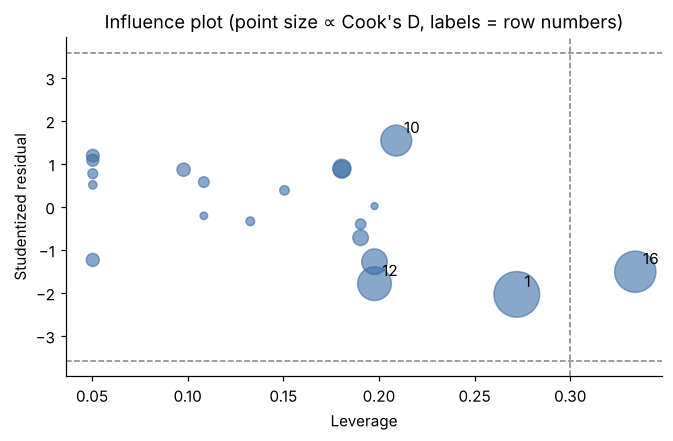

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(diag["leverage"], diag["stud. resid"], s=2000 * diag["Cook's D"] + 20, color="#3b6ea5", alpha=0.6)
for i in flagged.index:
    ax.annotate(str(i), (diag.loc[i, "leverage"], diag.loc[i, "stud. resid"]), xytext=(5, 5), textcoords="offset points")
ax.axvline(flags["leverage"], ls="--", color="grey", lw=1)
for s in (-flags["stud. resid"], flags["stud. resid"]):
    ax.axhline(s, ls="--", color="grey", lw=1)
ax.set(xlabel="Leverage", ylabel="Studentized residual", title="Influence plot (point size ∝ Cook's D, labels = row numbers)")
plt.show()

In [20]:
# Sensitivity check: refit without the flagged points and compare coefficients
robust = smf.ols("logY ~ X2 + X4", df.drop(index=flagged.index - 1)).fit()
pd.DataFrame({"all data": final.params, "flagged points removed": robust.params,
              "all data p": final.pvalues, "removed p": robust.pvalues})

,all data,flagged points removed,all data p,removed p
Intercept,1.1971,1.5983,0.0017,0.0008
X2,-0.1398,-0.1756,0.0762,0.0283
X4,0.0494,0.0385,0.0002,0.0085


Four points (rows 1, 10, 12 and 16) exceed at least one rule of thumb, mostly because they sit at the extremes of temperature or discharge rate. None is an outlier after the Bonferroni correction. Refitting without them keeps both effects in the same direction and of similar size: the temperature effect stays clearly significant, and the discharge-rate effect becomes *more* significant (p ≈ 0.03). The conclusions are robust, and **there's no justification for deleting data.** Points are removed only for a known reason, such as a recording error or a failed test, never just for being unusual.

## 7. Forecast for a new operating condition

The task is to predict cycles to failure at charge rate 1.5 A, discharge rate 4.5 A, depth of discharge 50%, temperature 25 °C and end-of-charge voltage 2.0 V. The final model uses only discharge rate and temperature.

Predictions are made on the log scale and converted back with 10^x. Back-transforming the mean of log(Y) gives the **median** number of cycles, not the mean, because the distribution of Y is skewed.

In [21]:
new = pd.DataFrame({"X1": [1.5], "X2": [4.5], "X3": [50], "X4": [25], "X5": [2.0]})

# Check that the new point is inside the range of the data (no extrapolation)
print(pd.DataFrame({"new": new.iloc[0], "data min": df[PREDICTORS].min(), "data max": df[PREDICTORS].max()}))
X_design = final.model.exog
x0 = np.array([1, 4.5, 25])
h0 = x0 @ np.linalg.inv(X_design.T @ X_design) @ x0
print(f"\nLeverage of new point = {h0:.3f} (max leverage in data = {infl.hat_matrix_diag.max():.3f})")

def forecast_table(model, newdata):
    pr = model.get_prediction(newdata).summary_frame(alpha=0.05)
    return pd.DataFrame({
        "point (median)": 10 ** pr["mean"],
        "95% CI low": 10 ** pr["mean_ci_lower"], "95% CI high": 10 ** pr["mean_ci_upper"],
        "95% PI low": 10 ** pr["obs_ci_lower"], "95% PI high": 10 ** pr["obs_ci_upper"],
    })

fc = pd.concat([forecast_table(final, new), forecast_table(m_orig, new)])
fc.index = ["Chosen model (X2 + X4)", "Original final model"]
fc.round(1)

     new  data min  data max
X1   1.5     0.375     1.625
X2   4.5     1.250     5.000
X3  50.0    43.200   100.000
X4  25.0     0.000    40.000
X5   2.0     1.980     2.020

Leverage of new point = 0.122 (max leverage in data = 0.334)


,point (median),95% CI low,95% CI high,95% PI low,95% PI high
Chosen model (X2 + X4),63.7,29.2,138.8,6.0,676.8
Original final model,67.0,20.7,217.0,5.0,899.0


**Reading the forecast.** The new point lies inside the range of the data, with lower leverage than several observed points, so this isn't an extrapolation. At 4.5 A discharge and 25 °C the model predicts a **median battery life of about 64 cycles**. The **95% confidence interval (about 29 to 139 cycles)** covers where the *median* life for these conditions probably lies. The **95% prediction interval (about 6 to 677 cycles)** covers where a *single new battery's* life will probably fall, so it's much wider.

That width isn't a calculation error. The model's residual standard deviation is about 0.46 on the log10 scale, a multiplicative factor of about 2.9 in either direction for an individual battery. A ±2 SE interval on the log scale becomes a very asymmetric, wide interval once converted back to cycles. The original model gives a similar point forecast but even wider intervals, because its extra terms add estimation uncertainty without explaining any more of the noise. That's an honest description of how variable these batteries are with only 20 test units.

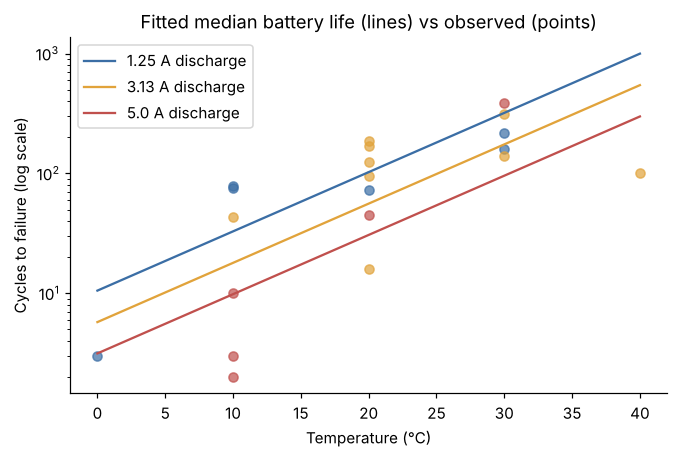

In [22]:
# Visualize the fitted model: predicted median cycles vs temperature at each discharge rate tested
grid = pd.DataFrame([(x2, t) for x2 in sorted(df["X2"].unique()) for t in np.linspace(0, 40, 41)], columns=["X2", "X4"])
grid["pred"] = 10 ** final.predict(grid)
colors = dict(zip(sorted(df["X2"].unique()), ["#3b6ea5", "#e1a33b", "#c0504d"]))
fig, ax = plt.subplots(figsize=(7, 4.2))
for x2, g in grid.groupby("X2"):
    ax.plot(g["X4"], g["pred"], color=colors[x2], label=f"{x2} A discharge")
    pts = df[df["X2"] == x2]
    ax.scatter(pts["X4"], pts["Y"], color=colors[x2], alpha=0.7)
ax.set_yscale("log"); ax.set(xlabel="Temperature (°C)", ylabel="Cycles to failure (log scale)",
                             title="Fitted median battery life (lines) vs observed (points)")
ax.legend(); plt.show()

## 8. Conclusions

1. **Temperature is the dominant factor.** Within the tested 0–40 °C range, warmer conditions are associated with much longer battery life (about +12% cycles per °C, strongly significant).
2. **Higher discharge rates probably shorten battery life** (about −27% cycles per amp). This effect improves prediction, but its significance is borderline (p ≈ 0.08), so it should be confirmed with more data.
3. Charge rate, depth of discharge and end-of-charge voltage showed **no detectable effect** with 20 observations, and **no interactions** were supported.
4. Individual batteries vary a lot even under similar conditions, so any single-battery forecast is uncertain by a factor of about 2.9 in each direction. For the requested conditions, the forecast median is about 64 cycles (95% prediction interval: 6 to 677).

**Limitations.** n = 20 is small: real but modest effects of the other variables could go undetected. The results only apply inside the tested ranges. Only one battery was tested at 0 °C and one at 40 °C, and the 40 °C battery lasted far less than the model predicts (101 cycles vs. about 540 predicted). The benefit of heat may level off or reverse at high temperatures, so the log-linear temperature effect shouldn't be trusted near the ends of the range. A larger replicated experiment would be needed to estimate the weaker effects.

## What changed from the original analysis

| Original approach | Problem | Revised approach |
|---|---|---|
| Chose log(Y) because its residual SD (0.46) was smaller than Y's (84.49) | The two SDs are in different units, so they can't be compared | Compared constant-variance tests, residual plots and a Box–Cox analysis |
| Used Durbin–Watson to rule out multicollinearity | Durbin–Watson tests residual autocorrelation, not multicollinearity | Computed VIFs (all ≈ 1) |
| Added variables by lowering a correlation cutoff | Arbitrary, and misses combinations | Compared all 31 subsets |
| Picked the model with the highest R² | R² always increases as terms are added, which rewards overfitting | Used adjusted R², AIC/BIC and leave-one-out cross-validation |
| Chose interactions X1×X3 and X2×X3 because those predictors were correlated with each other | That correlation doesn't imply an interaction, and X3's main effect was left out | Tested every interaction one at a time with its main effects included |
| Used a partial F-test against the weakest model (R² ≈ 10%) | Easy to pass, so it shows little | Nested F-tests against the competing best models |
| Recommended removing points flagged as outliers | Deleting data needs a known cause | Ran a sensitivity check instead; conclusions don't change |
| Suspected the wide prediction interval was a calculation error | It's the expected result of back-transforming from the log scale with noisy data | Explained the interval and labeled the back-transformed value as a median |
| Called results "reliable and not due to chance" because p < 0.05 | A p-value doesn't measure reliability, and a small p doesn't rule out chance | Reported effect sizes with confidence intervals and flagged the borderline effect |

**Result:** the original final model (6 terms, R² = 68.6%) has *worse* out-of-sample accuracy than a 2-term model (R² = 60.1%). The simpler model is better and easier to interpret.

## Appendix A: Sensitivity to the transformation

Box–Cox suggested λ ≈ 0.3. If I refit all subsets with Y^0.3, does the same model come out best?

In [23]:
df["Y03"] = df["Y"] ** 0.3
alt = pd.DataFrame([
    {"model": " + ".join(c), "Adj R²": (m := smf.ols("Y03 ~ " + " + ".join(c), df).fit()).rsquared_adj,
     "BIC": m.bic, "LOOCV MSE": loocv_mse(m)}
    for c in subsets])
alt.sort_values("LOOCV MSE").head(5).reset_index(drop=True)

,model,Adj R²,BIC,LOOCV MSE
0,X2 + X4,0.5429,60.0084,1.1122
1,X4,0.5137,59.3967,1.1147
2,X3 + X4,0.5110,61.3577,1.1585
3,X2 + X4 + X5,0.5481,61.5650,1.1622
4,X4 + X5,0.5114,61.3431,1.1987


With Y^0.3, X2 + X4 again has the lowest cross-validation error. BIC narrowly prefers temperature alone, which is consistent with the main analysis: temperature is the clear driver, and discharge rate is the weaker, borderline effect. The conclusions don't depend on the choice of transformation.